In [ ]:
!pip install lets-plot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.6 MB/s eta 0:00:00


In [ ]:
from sklearn.cluster import KMeans
from sklearn.model_selection import KFold
import numpy as np
import polars as pl
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)

# mortgage_rate = pl.read_csv("mortgage_rates.csv")
# mortgage_rate = (
#     mortgage_rate
#     .rename({"observation_date": "date", "MORTGAGE30US": "rate"})
#     .with_columns(pl.col("date").str.to_date("%Y-%m-%d"))
#     .group_by(year=pl.col("date").dt.year(), month=pl.col("date").dt.month())
#     .agg(pl.col("rate").mean())
# )

# 1. Load data
housing = pl.read_csv(
    "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing.csv"
)

onehot_cols = [
    "waterfront",
    "view",
    "condition",
    "grade_tier",
    "geo_cluster",
]

# Define downtown Seattle coordinates
center_long, center_lat = -122.3321, 47.6062

def prep(df):
    coords = df.select(["lat", "long"]).to_numpy()
    kmeans = KMeans(n_clusters=30, random_state=42)
    kmeans.fit(coords)

    cluster_labels = kmeans.predict(coords)

    return (
        df.with_columns(
            geo_cluster=pl.Series(cluster_labels).cast(pl.String),
            year=pl.col("date").str.slice(0, 4).cast(pl.Int32),
            month=pl.col("date").str.slice(4, 2).cast(pl.Int32),
            # day=pl.col("date").str.slice(6, 2).cast(pl.Int32),

            # grade_tier=pl.when(pl.col("grade").is_between(1, 3, closed="both"))
            # .then(pl.lit("low"))
            # .when(pl.col("grade").is_between(4, 10, closed="both"))
            # .then(pl.lit("average_to_good"))
            # .otherwise(pl.lit("high")),

            house_age=pl.col("date").str.slice(0, 4).cast(pl.Int32) - pl.col("yr_built"),

            yrs_since_renev=pl.col('date').str.slice(0, 4).cast(pl.Int32) - pl.col('yr_renovated'),

            dist_to_center=(
                (pl.col("lat") - center_lat) ** 2
                + (pl.col("long") - center_long) ** 2
            ).sqrt(),

            #  basement_ratio = pl.col("sqft_basement") / pl.col("sqft_living")
        )
        # .drop("date", "id", "sqft_basement")
        .drop("date", "id")
        .to_dummies(columns=onehot_cols)
        # .join(mortgage_rate, on=["year", "month"], how="left")
    )

# Prep the training housing data
housing = prep(housing)

X = housing.drop(["price"])
y = housing["price"]

# Convert Polars to NumPy arrays for K-Fold indexing
X_np = X.to_numpy()
y_np = y.to_numpy()

# Set up 5-Fold Cross-Validation
# (Remove random_state if you want it to shuffle differently every single time you run it)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Lists to collect scores across folds
rmse_scores = []
mse_scores = []
mae_scores = []
mape_scores = []
r2_scores = []

# --- K-FOLD LOOP ---
for train_index, test_index in kf.split(X_np):
    X_train, X_test = X_np[train_index], X_np[test_index]
    y_train, y_test = y_np[train_index], y_np[test_index]

    # Log-transform target for training
    y_train_log = np.log1p(y_train)

    model = XGBRegressor()
    model.fit(X_train, y_train_log)

    # Predict on log scale and convert back to actual dollars
    pred_log = model.predict(X_test)
    pred_actual = np.expm1(pred_log)

    # Evaluate fold and store metrics
    rmse_scores.append(root_mean_squared_error(y_test, pred_actual))
    mse_scores.append(mean_squared_error(y_test, pred_actual))
    mae_scores.append(mean_absolute_error(y_test, pred_actual))
    mape_scores.append(mean_absolute_percentage_error(y_test, pred_actual))
    r2_scores.append(r2_score(y_test, pred_actual))

# --- PRINT AVERAGE RESULTS ---
print(housing.height)
print("--- Average Cross-Validation Results (5 Folds) ---")
print(f"Root Mean Squared Error: {np.mean(rmse_scores)}")
print(f"Mean Squared Error: {np.mean(mse_scores)}")
print(f"Mean Absolute Error: {np.mean(mae_scores)}")
print(f"Mean Absolute Percentage Error: {np.mean(mape_scores)}")
print(f"R2 Score: {np.mean(r2_scores)}")



# # Mini holdout testing (have to do log scale)
# test = pl.read_csv(
#     "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing_holdout_test_mini.csv"
# )
test = pl.read_csv(
    "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing_holdout_test.csv"
)

test = prep(test)

# dummy columns holdout missing
test = test.with_columns(
    [
        pl.lit(0).alias(col)
        for col in X.columns
        if col not in test.columns
    ]
)

test = test.select(X.columns)

# Because the model was trained on log prices, we predict, expm1 to get real dollars, then int
predictions = np.expm1(model.predict(test)).astype(int)

predictions = pl.DataFrame(predictions, schema=["price"])

predictions.write_csv("team3-module3-predictions.csv")
print(housing.columns)

# This doesn't matter
# n = len(y_test)   # n of test observations
# p = X_test.shape[1]   # n of predictors
# adj_r2 = 1 - (1 - r2_result) * (n - 1) / (n - p - 1)
# print(f'Adjusted R2 Score: {adj_r2}')

20000
--- Average Cross-Validation Results (5 Folds) ---
Root Mean Squared Error: 116956.65830385499
Mean Squared Error: 13723868904.789074
Mean Absolute Error: 64596.032245703136
Mean Absolute Percentage Error: 0.12068684582897235
R2 Score: 0.8979979375301769
['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront_0', 'waterfront_1', 'view_0', 'view_1', 'view_2', 'view_3', 'view_4', 'condition_1', 'condition_2', 'condition_3', 'condition_4', 'condition_5', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'price', 'geo_cluster_0', 'geo_cluster_1', 'geo_cluster_10', 'geo_cluster_11', 'geo_cluster_12', 'geo_cluster_13', 'geo_cluster_14', 'geo_cluster_15', 'geo_cluster_16', 'geo_cluster_17', 'geo_cluster_18', 'geo_cluster_19', 'geo_cluster_2', 'geo_cluster_20', 'geo_cluster_21', 'geo_cluster_22', 'geo_cluster_23', 'geo_cluster_24', 'geo_cluster_25', 'geo_cluster_26', 'geo_cluster_27', 'geo_clust

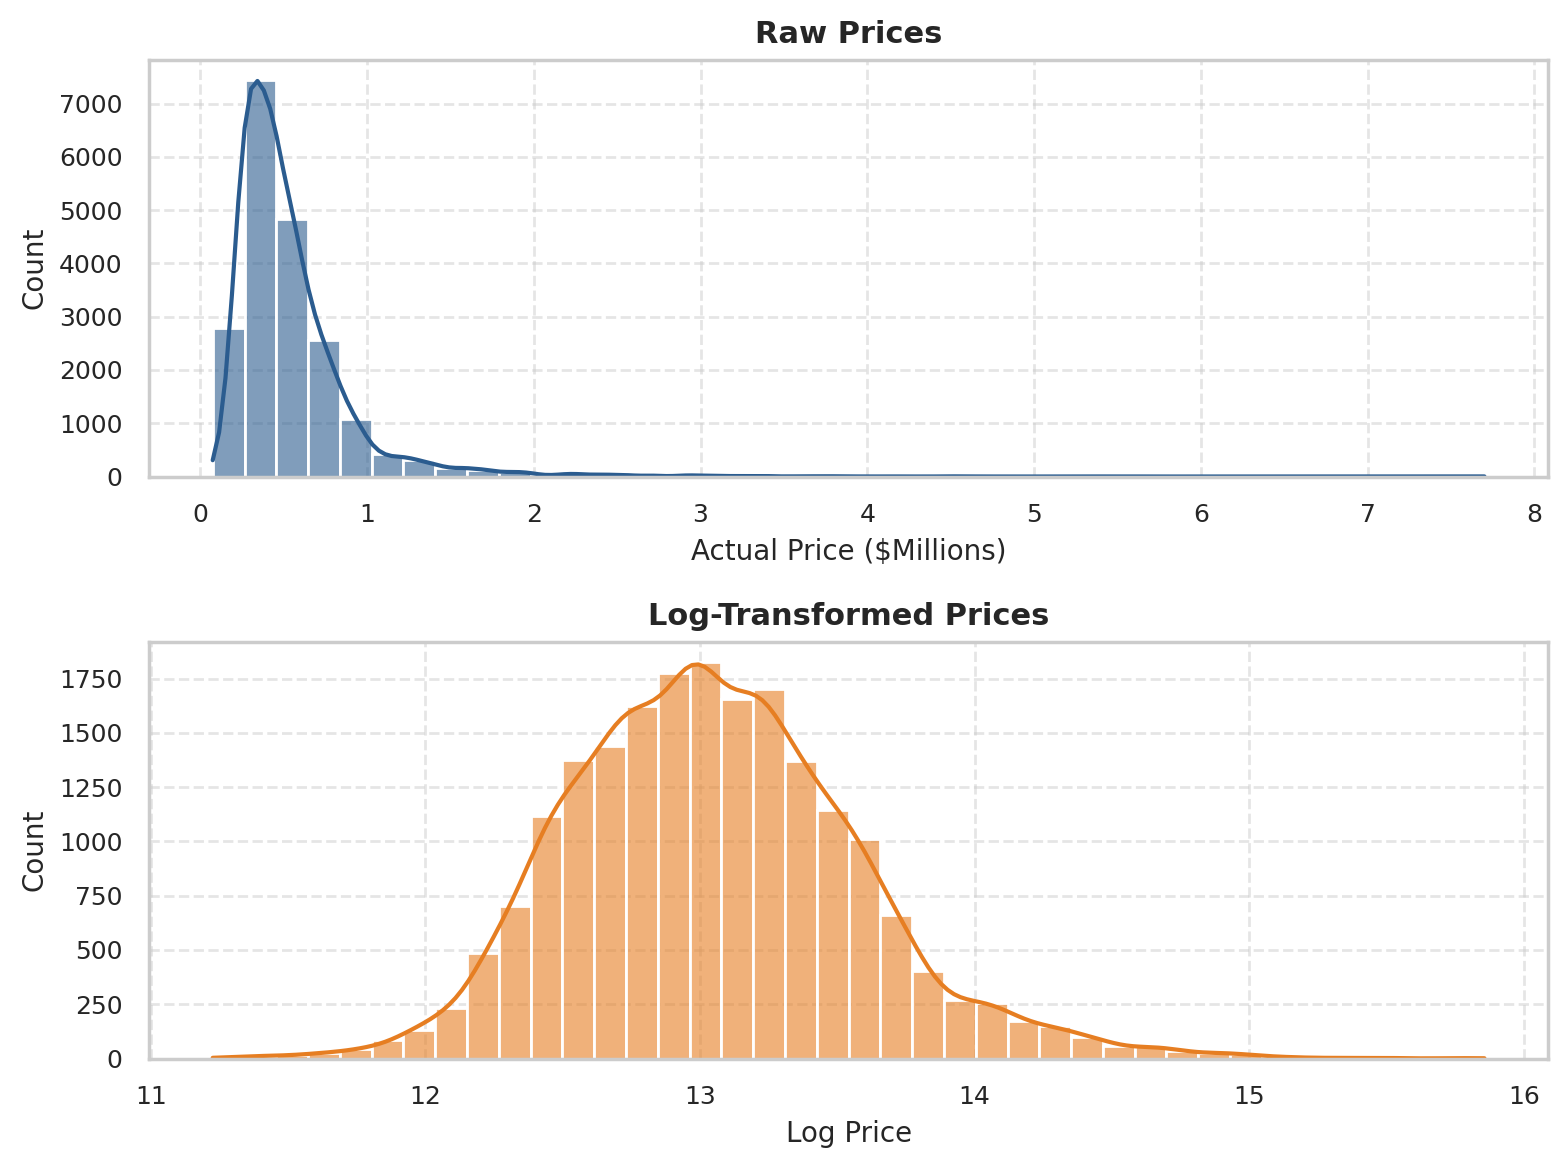

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Set up a stacked vertical layout (2 rows, 1 column) to save horizontal space
sns.set_theme(style='whitegrid', font='sans-serif')
fig, axes = plt.subplots(
    2, 1, figsize=(8, 6), dpi=200
)  # Taller and narrower footprint

# Scale raw prices to millions
raw_prices_millions = housing['price'].to_numpy() / 1e6

# 1. Raw Price Distribution (Top)
sns.histplot(
    raw_prices_millions,
    kde=True,
    ax=axes[0],
    color='#2b5c8f',
    bins=40,
    alpha=0.6,
)
axes[0].set_title(
    'Raw Prices', fontsize=11, fontweight='bold', pad=6
)
axes[0].set_xlabel('Actual Price ($Millions)', fontsize=10)
axes[0].set_ylabel('Count', fontsize=10)

# 2. Log-Transformed Price Distribution (Bottom)
log_prices = np.log1p(housing['price'].to_numpy())
sns.histplot(
    log_prices, kde=True, ax=axes[1], color='#e67e22', bins=40, alpha=0.6
)
axes[1].set_title(
    'Log-Transformed Prices', fontsize=11, fontweight='bold', pad=6
)
axes[1].set_xlabel('Log Price', fontsize=10)
axes[1].set_ylabel('Count', fontsize=10)

# Clean up tick sizes and grid styling across both subplots
for ax in axes:
  ax.tick_params(labelsize=9)
  ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
from lets_plot import *

tree_importance = (
    pl.DataFrame({
        "feature": X.columns,
        "importance": model.feature_importances_
    })
    .sort("importance", descending=True)
)

tree_importance.head(10)

ggplot(
    tree_importance.head(10).sort("importance"),
    aes(x="importance", y="feature")
) + \
    geom_bar(stat="identity") + \
    labs(
        title="Housing Attributes by Model Importance",
        x="Importance",
        y="Feature"
    )

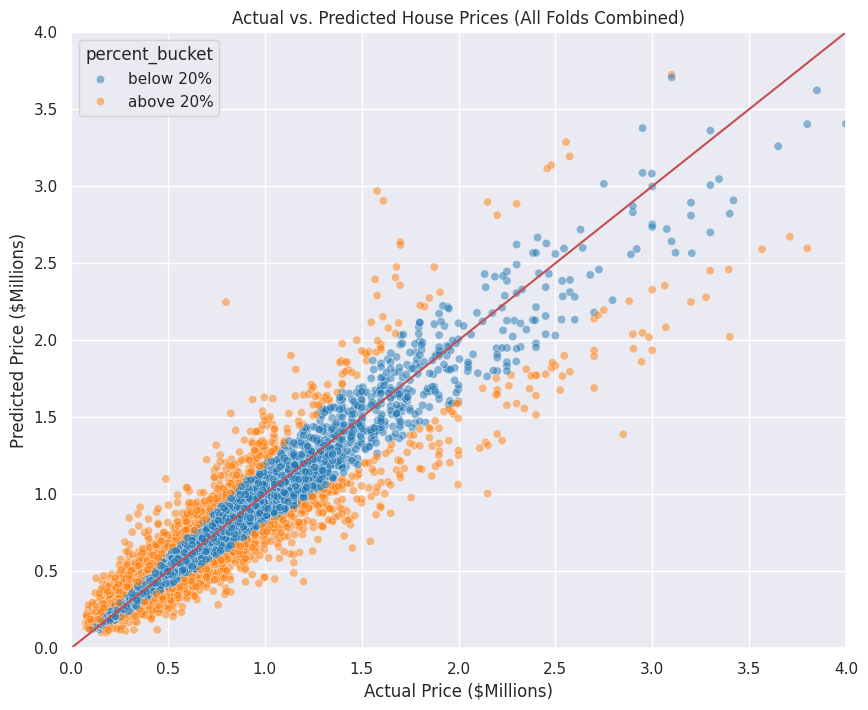

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Lists to hold all actuals and predictions across all folds
all_y_test = []
all_preds = []

# --- K-FOLD LOOP ---
for train_index, test_index in kf.split(X_np):
    X_train, X_test = X_np[train_index], X_np[test_index]
    y_train, y_test = y_np[train_index], y_np[test_index]

    # Log-transform target for training
    y_train_log = np.log1p(y_train)

    model = XGBRegressor()
    model.fit(X_train, y_train_log)

    # Predict on log scale and convert back to actual dollars
    pred_log = model.predict(X_test)
    pred_actual = np.expm1(pred_log)

    # Save them to our master lists
    all_y_test.extend(y_test)
    all_preds.extend(pred_actual)

# --- PLOTTING CODE ---

# --- PLOTTING CODE ---

# 1. Combine all actuals and predictions into a pandas DataFrame and scale to millions
eval_df = pd.DataFrame(
    {
        'price': [y / 1e6 for y in all_y_test],
        'predictions': [p / 1e6 for p in all_preds],
    }
)

# 2. Calculate differences and error buckets
eval_df['difference'] = eval_df['price'] - eval_df['predictions']
eval_df['percent_difference'] = abs(
    eval_df['difference'] / eval_df['price']
)
eval_df['percent_bucket'] = [
    'above 20%' if i >= 0.2 else 'below 20%'
    for i in eval_df['percent_difference']
]

# 3. Set up plot styling and limits (now using 0 to 4 instead of millions)
sns.set(rc={'figure.figsize': (10, 8)})
color_dict = {'below 20%': 'tab:blue', 'above 20%': 'tab:orange'}
xlims = (0, 4)
ylims = (0, 4)

# 4. Create the scatter plot
ax = sns.scatterplot(
    data=eval_df,
    x='price',
    y='predictions',
    hue='percent_bucket',
    palette=color_dict,
    alpha=0.5,  # Added transparency so overlapping points are visible
)

# 5. Plot the perfect prediction line (45-degree red line)
ax.plot(xlims, xlims, color='r')
ax.set_xlim(xlims)
ax.set_ylim(ylims)

# 6. Update axis labels to indicate millions
plt.xlabel('Actual Price ($Millions)')
plt.ylabel('Predicted Price ($Millions)')
plt.title('Actual vs. Predicted House Prices (All Folds Combined)')
plt.show()

In [ ]:
# Calculate the confidence percentages (within 5%, 10%, and 20%) using the collected K-Fold results
eval_df['abs_pct_diff'] = abs(eval_df['difference'] / eval_df['price'])

percents = [5, 10, 20]
for pct in percents:
    pct_val = pct / 100
    within_pct = (eval_df['abs_pct_diff'] <= pct_val).mean() * 100
    print(f"Percent of houses predicted within {pct}% of actual price: {within_pct:.2f}%")

Percent of houses predicted within 5% of actual price: 32.23%
Percent of houses predicted within 10% of actual price: 56.80%
Percent of houses predicted within 20% of actual price: 83.05%


In [ ]:
from lets_plot import *

LetsPlot.setup_html()

# Create a geographic scatter plot of prices using longitude and latitude
(
    ggplot(housing, aes(x='long', y='lat', color='price'))
    + geom_point(alpha=0.5, size=1.5)
    + scale_color_gradient(
        low='blue',
        high='red',
        trans='log10',
        breaks=[100000, 250000, 500000, 1000000, 2500000, 5000000],
        labels=['$100K', '$250K', '$500K', '$1M', '$2.5M', '$5M']
    )
    + coord_fixed(ratio=1.3)  # Fixes the map distortion
    + labs(
        title='Housing Prices by Geographic Location',
        x='Longitude',
        y='Latitude',
        color='Price',
    )
    + theme_minimal()
)

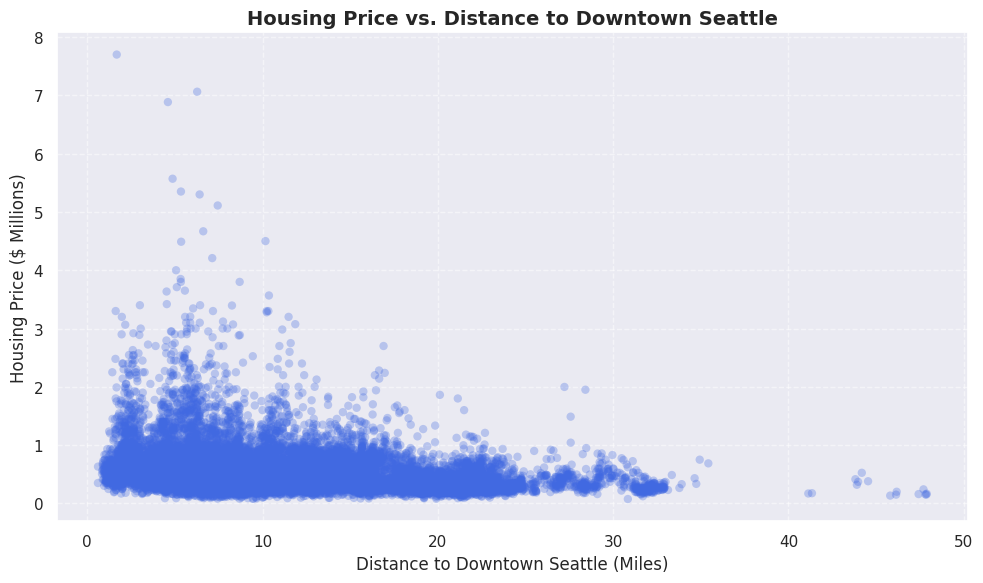

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Seattle's latitude for longitude scaling correction
center_lat = 47.6062

# Convert coordinates to approximate miles directly from the existing dataframe
lat_diff_miles = (housing["lat"].to_numpy() - center_lat) * 69.0
long_diff_miles = (housing["long"].to_numpy() - -122.3321) * (
    69.0 * np.cos(np.radians(center_lat))
)
distance_miles = np.sqrt(lat_diff_miles**2 + long_diff_miles**2)

prices_in_millions = housing["price"].to_numpy() / 1_000_000

plt.figure(figsize=(10, 6))
plt.scatter(
    distance_miles,
    prices_in_millions,
    alpha=0.3,
    color="royalblue",
    edgecolors="none",
)

plt.title(
    "Housing Price vs. Distance to Downtown Seattle",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Distance to Downtown Seattle (Miles)", fontsize=12)
plt.ylabel("Housing Price ($ Millions)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
holdout = pl.read_csv("https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/housing_holdout_test.csv")
holdout.describe()


import polars as pl

cols = ["price", "rate"]

cols = [
    "bedrooms", "bathrooms", "floors", "sqft_living",
    "sqft_lot", "price", "yrs_since_renev", "house_age",
]

summary = pl.DataFrame({
    "variable": cols,
    "mean": [housing[c].mean() for c in cols],
    "median": [housing[c].median() for c in cols],
    "std": [housing[c].std() for c in cols],
}).with_columns(pl.col("mean", "median", "std").round(2))

summary

variable,mean,median,std
str,f64,f64,f64
"""bedrooms""",3.37,3.0,0.93
"""bathrooms""",2.12,2.25,0.77
"""floors""",1.5,1.5,0.54
"""sqft_living""",2079.88,1910.0,919.43
"""sqft_lot""",15015.33,7620.0,39701.35
"""price""",539436.71,450000.0,366433.44
"""yrs_since_renev""",1931.59,2014.0,397.88
"""house_age""",43.22,39.0,29.38


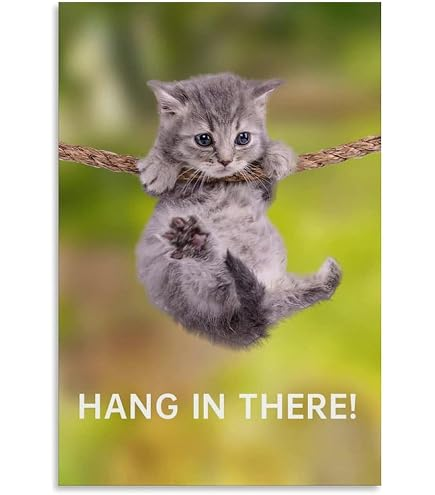

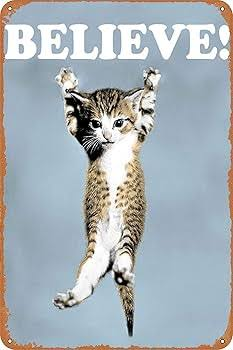